# Perspective Transform: Straightening a Traffic Sign

A camera sees a flat object at an angle, so a rectangle appears as a **quadrilateral** and parallel lines converge. A **perspective transform** maps that quadrilateral back to a rectangle, as if the camera looked straight at the object. This is the core of a **bird's-eye view** in lane detection, and it gives a classifier a front-on view of a traffic sign.

This notebook does the following on a speed limit sign photographed at an angle:
1. Explains how a perspective transform differs from the affine transforms in the previous notebook.
2. Marks the four corners of the sign and checks them on the image.
3. Computes the 3 × 3 perspective matrix from the four corner pairs.
4. Warps the sign to a straight, rectangular view.
5. Checks the matrix by mapping the corners and measuring the error.
6. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, perspective matrix and warping
- `matplotlib`: displaying images
- `numpy`: array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. Perspective transform and homography

An affine transform (rotation, translation, scaling) keeps parallel lines parallel. A perspective transform does not: two rails that converge into the distance can be made parallel again. It is described by a $3 \times 3$ matrix $H$, called a **homography**, and uses homogeneous coordinates:

$$\begin{bmatrix} x' \\ y' \\ w \end{bmatrix} = H \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}, \qquad x_{\text{out}} = \frac{x'}{w}, \quad y_{\text{out}} = \frac{y'}{w}$$

The division by $w$ is what produces the perspective effect. $H$ has 8 free values, because its last entry is fixed to 1 and the overall scale does not change the result. Each pair of matching points gives 2 equations, so **4 point pairs** are exactly enough. `cv2.getPerspectiveTransform` solves that system.

With exactly 4 points, a single wrong corner gives a wrong matrix. With noisy points, use more points and `cv2.findHomography` with RANSAC, which ignores outliers.

## 3. Configuration

- `INPUT_PATH`: the sign photo.
- `SOURCE_POINTS`: the four corners of the sign in the photo, in pixels, in the order top-left, top-right, bottom-right, bottom-left. They were read from the image by eye.
- `OUTPUT_SIZE`: the `(width, height)` of the straightened sign in pixels. It follows the sign's proportions, which are close to 3:4 here.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("Speed_Sign_View_2.jpg")
OUTPUT_DIR = Path("output")

SOURCE_POINTS = np.float32([
    [185, 50],   # top-left
    [452, 150],  # top-right
    [523, 515],  # bottom-right
    [150, 478],  # bottom-left
])
OUTPUT_SIZE = (300, 400)  # (width, height) of the straightened sign

## 4. Load the image and check the corners

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `draw_polygon` draws the four points and the outline on a copy of the image, so the chosen corners can be checked by eye.
- `save_image` writes an image and checks the result.

Check that the red outline follows the outer edge of the sign before going on.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def draw_polygon(img: np.ndarray, points: np.ndarray) -> np.ndarray:
    """Return a copy of the image with the outline and corner points drawn in red."""
    out = img.copy()
    pts = points.astype(np.int32).reshape(-1, 1, 2)
    cv2.polylines(out, [pts], isClosed=True, color=(0, 0, 255), thickness=2)
    for x, y in points.astype(int):
        cv2.circle(out, (x, y), 5, (0, 0, 255), thickness=-1)
    return out


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Image size (height, width): 600, 800


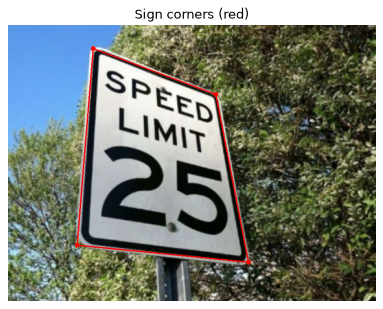

In [4]:
image = load_image(INPUT_PATH)
height, width = image.shape[:2]
print(f"Image size (height, width): {height}, {width}")

marked = draw_polygon(image, SOURCE_POINTS)
show_images({"Sign corners (red)": marked})

## 5. Compute the perspective matrix

The destination points are the corners of an upright rectangle of size `OUTPUT_SIZE`, in the same order as the source points. `cv2.getPerspectiveTransform` returns the $3 \times 3$ matrix $H$ that maps each source corner to its destination corner.

In [5]:
out_w, out_h = OUTPUT_SIZE
DESTINATION_POINTS = np.float32([
    [0, 0],           # top-left
    [out_w, 0],       # top-right
    [out_w, out_h],   # bottom-right
    [0, out_h],       # bottom-left
])

H = cv2.getPerspectiveTransform(SOURCE_POINTS, DESTINATION_POINTS)
print("Perspective matrix H:\n", np.round(H, 4))

Perspective matrix H:
 [[ 7.948000e-01  6.500000e-02 -1.502876e+02]
 [-4.410000e-01  1.177500e+00  2.271270e+01]
 [-9.000000e-04  9.000000e-04  1.000000e+00]]


## 6. Warp the sign

`cv2.warpPerspective` works like `warpAffine` from the previous notebook. For each pixel of the output it looks up the matching position in the photo, using $H^{-1}$, and interpolates between pixels where needed.

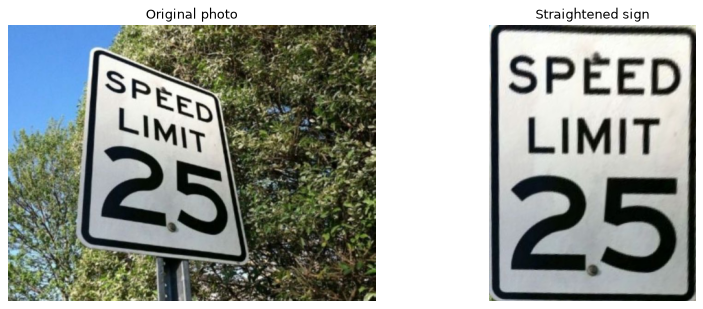

In [6]:
warped = cv2.warpPerspective(image, H, OUTPUT_SIZE)

show_images({
    "Original photo": image,
    "Straightened sign": warped,
})

## 7. Check the matrix

If the corners are right, mapping each source point with $H$ gives its destination point. `cv2.perspectiveTransform` applies $H$ to points, including the division by $w$. The error below is the distance in pixels between the mapped points and the destination corners. It should be close to zero, which only shows that the matrix fits the four points. It does not show that the four points were placed correctly on the sign, which is why section 4 checks them by eye.

In [7]:
mapped = cv2.perspectiveTransform(SOURCE_POINTS.reshape(-1, 1, 2), H).reshape(-1, 2)
errors = np.linalg.norm(mapped - DESTINATION_POINTS, axis=1)

for name, error in zip(["top-left", "top-right", "bottom-right", "bottom-left"], errors):
    print(f"{name:>13}: error {error:.4f} px")

     top-left: error 0.0000 px
    top-right: error 0.0000 px
 bottom-right: error 0.0000 px
  bottom-left: error 0.0000 px


## 8. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [8]:
stem = INPUT_PATH.stem
outputs = {
    "corners_marked": marked,
    "straightened": warped,
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result)

Saved output/Speed_Sign_View_2_corners_marked.jpg
Saved output/Speed_Sign_View_2_straightened.jpg


## 9. Conclusion

- A **perspective transform** maps a quadrilateral to a rectangle. It is a $3 \times 3$ homography, and it needs four point pairs.
- Unlike an affine transform, it does **not** keep parallel lines parallel. That is exactly what removes the perspective effect.
- The **four corners** decide the result. Check them on the image before trusting the warp, and use more points with RANSAC if the corners are noisy.
- The **output size** sets the resolution of the straightened image. Choose the proportions of the real object, not the size of the photo, so that the object is not stretched.
- The same method turns a road photo into a **bird's-eye view** for lane detection, and it gives a traffic sign classifier a front-on view.